# Racing data: audit and cleaning

This notebook prepares reproducible datasets for **question 4: field size and favourite success**, and **winner prediction**. Each runner row is a horse's entry in a race; each race row describes an event. The join key is `race_instance_uid`.

The workflow is: inspect the source, make low-risk corrections, interpret outcomes, assess complete races, and report eligibility and coverage. Question 2 is outside this notebook's scope.

**Principle:** preserve source records, correct clear formatting issues, and exclude ambiguous races from the initial task datasets without inventing results. Exclusion does not mean a record is necessarily erroneous.

**Run:** place this file beside `data/` (or in `notebooks/`), select the project Python environment, and run all cells in order. Requires pandas, NumPy and Matplotlib. SQLite is read-only. Outputs are intentionally cleared in this reorganised version: rerun locally to produce submission evidence. Exports are optional and never modify the database.

## 1. Configuration and source data
Set `DB_PATH_OVERRIDE` if automatic discovery cannot find exactly one database. Leave exports disabled for the first run.

In [ ]:
from pathlib import Path
from contextlib import closing
import sqlite3
import json
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 60)

# Set an explicit path if automatic discovery finds zero or multiple databases.
DB_PATH_OVERRIDE = None  # e.g. Path(r'C:\Users\orman\Documents\horse-racing-assignment\data\race_runner_data.db')
EXPORT_RESULTS = False 


if DB_PATH_OVERRIDE is not None:
    DB_PATH = Path(DB_PATH_OVERRIDE).expanduser().resolve()
else:
    candidates = sorted(set(p.resolve() for folder in [Path.cwd()/ 'data', Path.cwd().parent / 'data']
                            if folder.is_dir() for p in folder.glob('*.db')))
    if len(candidates) != 1:
        raise FileNotFoundError(f'Set DB_PATH_OVERRIDE to the exact database path. Found: {candidates}; cwd: {Path.cwd()}')
    DB_PATH = candidates[0]
assert DB_PATH.is_file(), f'File not found: {DB_PATH}'
PROJECT_ROOT = DB_PATH.parent.parent if DB_PATH.parent.name == 'data' else DB_PATH.parent
print('Database:', DB_PATH)
print('Python:', platform.python_version(), '| pandas:', pd.__version__)


Database: C:\Users\orman\OneDrive\Documents\horse-racing-assignment\data\race_runner_data.db
Python: 3.14.6 | pandas: 3.0.6


In [19]:
with closing(sqlite3.connect(DB_PATH.as_uri() + '?mode=ro', uri=True)) as conn:
    tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn)
    display(tables)
    assert {'races', 'runners'}.issubset(set(tables['name'])), 'Expected tables are missing.'
    schemas = {t: pd.read_sql_query(f'PRAGMA table_info({t})', conn) for t in ['races', 'runners']}
    races_raw = pd.read_sql_query('SELECT * FROM races', conn)
    runners_raw = pd.read_sql_query('SELECT * FROM runners', conn)

source_summary = pd.DataFrame([
    {"table": name, "rows": len(frame), "columns": frame.shape[1],
     "memory_mib": round(frame.memory_usage(deep=True).sum()/1024**2, 1)}
    for name, frame in [("races", races_raw), ("runners", runners_raw)]
])
display(source_summary)
# Full schemas remain available in `schemas` for inspection.


,name
0,races
1,runners


,table,rows,columns,memory_mib
0,races,70719,17,52.4
1,runners,710982,35,1018.5


## 2. Basic cleaning and missingness
Remove exact duplicates, trim text, and convert empty strings to missing values. Keep the originals in `races_raw` and `runners_raw`. Do not globally replace zeros or impute missing values: their meanings depend on the field. Missing currency values and draw values may be structurally inapplicable.

In [20]:
cleaning_log = []
def standardise(frame, name):
    before = len(frame)
    out = frame.drop_duplicates().copy()
    exact_removed = before - len(out)
    for col in out.select_dtypes(include=['object', 'string']).columns:
        out[col] = out[col].astype('string').str.strip().replace('', pd.NA)
    normalised_before = len(out)
    out = out.drop_duplicates().reset_index(drop=True)
    cleaning_log.append({'table': name, 'input_rows': before,
                         'exact_duplicates_removed': exact_removed,
                         'duplicates_after_text_cleaning': normalised_before-len(out),
                         'remaining_rows': len(out)})
    return out

races = standardise(races_raw, 'races')
runners = standardise(runners_raw, 'runners')
display(pd.DataFrame(cleaning_log))

def missingness(frame):
    return pd.DataFrame({'dtype': frame.dtypes.astype(str), 'missing': frame.isna().sum(),
                         'missing_pct': frame.isna().mean().mul(100).round(2),
                         'unique_nonmissing': frame.nunique()}).sort_values('missing_pct', ascending=False)
missing_races = missingness(races)
missing_runners = missingness(runners)
display(missing_races)
display(missing_runners)


,table,input_rows,exact_duplicates_removed,duplicates_after_text_cleaning,remaining_rows
0,races,70719,0,0,70719
1,runners,710982,0,0,710982


,dtype,missing,missing_pct,unique_nonmissing
prizes_total_eur,float64,56196,79.46,102
prizes_total_gbp,float64,20570,29.09,632
race_class,string,20573,29.09,6
direction_of_racing,string,6146,8.69,4
race_description,string,6061,8.57,5839
distance_yards,float64,0,0.00,1476
race_group_uid,string,0,0.00,15
going_type_code,string,1,0.00,16
distance_furlong,float64,0,0.00,1476
race_type_code,string,0,0.00,5


,dtype,missing,missing_pct,unique_nonmissing
final_race_outcome_is_dnf,string,710982,100.00,0
final_race_outcome_is_dq_status,string,710673,99.96,7
final_race_outcome_is_dnf_status,string,660010,92.83,11
draw,float64,315107,44.32,37
distance_from_horse,float64,121275,17.06,139
result_distance_from_next_horse_lengths,float64,121278,17.06,140
result_distance_from_winner_lengths,float64,121278,17.06,3189
distance_from_winner,float64,121278,17.06,3189
result_distance_from_horse_lengths,float64,121275,17.06,139
final_race_outcome_position,float64,50972,7.17,35


## 3. Types, dates and source codes
Parse dates and numerical values, retaining a diagnostic record of every failed conversion. Check coverage rather than assuming complete calendar years. Timezone and intraday availability need confirmation before constructing historical features.

The source review found the DNF flag unpopulated, so status text supplies the DNF information. Explicit 0/1 mappings are used for participation, favourite and disqualification flags; unrecognised values remain unknown.

In [21]:
conversion_records = []
def convert(frame, table, col, kind):
    if col not in frame:
        raise KeyError(f'Missing required column: {table}.{col}')
    original = frame[col].copy()
    parsed = pd.to_datetime(original, errors='coerce') if kind == 'date' else pd.to_numeric(original, errors='coerce')
    failed = original.notna() & parsed.isna()
    for idx in frame.index[failed]:
        conversion_records.append({'table': table, 'row_index': int(idx), 'column': col,
                                   'original_value': str(original.loc[idx]),
                                   'race_instance_uid': frame.loc[idx, 'race_instance_uid']})
    frame[col] = parsed

for col in ['race_datetime']:
    convert(races, 'races', col, 'date')
for col in ['race_datetime', 'race_date']:
    convert(runners, 'runners', col, 'date')
for col in ['distance_yards', 'distance_furlong', 'prizes_total_gbp', 'prizes_total_eur', 'prize_winner']:
    convert(races, 'races', col, 'numeric')
for col in ['final_race_outcome_position', 'number_of_runners', 'draw', 'horse_age',
            'rp_postmark', 'rp_topspeed', 'is_non_runner', 'favourite_flag', 'final_race_outcome_is_dq']:
    convert(runners, 'runners', col, 'numeric')
conversion_issues = pd.DataFrame(conversion_records, columns=['table','row_index','column','original_value','race_instance_uid'])
print('Conversion failures:', len(conversion_issues))
display(conversion_issues.head(30))

year_coverage = pd.concat([races['race_datetime'].dt.year.value_counts().rename('race_rows'),
                           runners['race_date'].dt.year.value_counts().rename('runner_rows')], axis=1).sort_index()
display(year_coverage)
print('Race date range:', races['race_datetime'].min(), 'to', races['race_datetime'].max())


Conversion failures: 0


,table,row_index,column,original_value,race_instance_uid


,race_rows,runner_rows
2021,3097,32897
2022,14655,142902
2023,14471,143254
2024,14250,144106
2025,14440,139955
2026,9806,107868


Race date range: 2021-10-08 13:00:00 to 2026-09-21 20:12:00


In [22]:
for col in ['is_non_runner', 'favourite_flag', 'final_race_outcome_is_dnf',
            'final_race_outcome_is_dnf_status', 'final_race_outcome_is_dq',
            'final_race_outcome_is_dq_status']:
    print(col)
    display(runners[col].value_counts(dropna=False).head(40).to_frame('rows'))


is_non_runner


,rows
is_non_runner,
0,653798
1,57184


favourite_flag


,rows
favourite_flag,
0,635627
1,75355


final_race_outcome_is_dnf


...

,rows
final_race_outcome_is_dnf_status,
<NA>,660010
Pulled Up,37000
Fell,7120
Unseated Rider,5105
Brought Down,483
Ran Out,392
Refused To Race,311
Slipped Up,244
Refused,162


final_race_outcome_is_dq


,rows
final_race_outcome_is_dq,
0,710680
1,302


final_race_outcome_is_dq_status


,rows
final_race_outcome_is_dq_status,
<NA>,710673
Last Disq,119
1D,112
2D,45
3D,20
4D,6
5D,5
6D,2


## 4. Validate the join and quarantine structural conflicts
A runner must match at most one race. Conflicting race records are removed from the lookup, not resolved arbitrarily. Races with conflicting entry identifiers or duplicate race–horse pairs are excluded as a whole; otherwise dropping one horse could distort field size or the outcome. Missing horse IDs are reported, but do not alone invalidate a race result.

Records without a race ID remain in diagnostic tables. Source races without runner records will be counted separately in the final summary.

In [23]:
duplicate_races = races.loc[races['race_instance_uid'].notna() & races['race_instance_uid'].duplicated(keep=False)].copy()
dup_runner_mask = runners['runner_uid'].notna() & runners['runner_uid'].duplicated(keep=False)
dup_pair_mask = (runners[['race_instance_uid','horse_uid']].notna().all(axis=1)
                 & runners.duplicated(['race_instance_uid','horse_uid'], keep=False))
structural_mask = dup_runner_mask | dup_pair_mask | runners['runner_uid'].isna()
structural_runner_rows = runners.loc[structural_mask].copy()
missing_race_id_rows = runners.loc[runners['race_instance_uid'].isna()].copy()
bad_entry_race_ids = set(structural_runner_rows['race_instance_uid'].dropna())
conflicting_race_ids = set(duplicate_races['race_instance_uid'])

race_lookup = races.loc[races['race_instance_uid'].notna() & ~races['race_instance_uid'].isin(conflicting_race_ids)].copy()
assert race_lookup['race_instance_uid'].is_unique
master = runners.loc[runners['race_instance_uid'].notna()].merge(
    race_lookup, on='race_instance_uid', how='left', validate='many_to_one',
    suffixes=('_runner','_race'), indicator='race_match')
assert len(master) == runners['race_instance_uid'].notna().sum()
master['structural_entry_issue'] = master['race_instance_uid'].isin(bad_entry_race_ids)
print('Conflicting race IDs:', len(conflicting_race_ids))
print('Affected entry race IDs:', len(bad_entry_race_ids))
print('Runner rows missing race ID:', len(missing_race_id_rows))
print('Race rows missing race ID:', races['race_instance_uid'].isna().sum())
print('Missing horse IDs:', runners['horse_uid'].isna().sum())
print('Race IDs without runner records:', len(set(race_lookup['race_instance_uid']) - set(runners['race_instance_uid'].dropna())))
display(master['race_match'].value_counts().to_frame('rows'))
# Detailed conflicts remain in structural_runner_rows and duplicate_races.


Conflicting race IDs: 0
Affected entry race IDs: 3
Runner rows missing race ID: 0
Race rows missing race ID: 0
Missing horse IDs: 0
Race IDs without runner records: 491


,rows
race_match,
both,710982
left_only,0
right_only,0


## 5. Interpret participation and outcomes

| Record | Initial policy |
|---|---|
| Non-runner with zero or missing position | Retain in master; exclude from starter datasets |
| Starter with a positive integer position and no conflicting status | Position 1 is a winner; other positions are losses |
| Starter with a recognised DNF, missing position and no conflict | Retain as a non-winner |
| Unexplained zero/missing result, unfamiliar status or contradiction | Exclude the affected race |
| Disqualification | Exclude the affected race from the initial datasets |

Zero is a common **non-runner placeholder**, not a finishing rank. A zero for a supposed starter is not automatically a loss. The DNF list below is deliberately conservative; unfamiliar descriptions are not automatically reclassified. `is_winner` stays missing where the outcome cannot be assigned safely.

In [24]:
NON_RUNNER_MAP = {0: False, 1: True}
FAVOURITE_MAP = {0: False, 1: True}
DQ_MAP = {0: False, 1: True}
# Explicit status list for this initial conservative policy.
DNF_STATUSES = {'pulled up', 'fell', 'unseated rider', 'refused', 'ran out', 'brought down', 'slipped up'}
EMPTY_STATUS_LABELS = {'', 'none', 'nan', 'null'}
DNF_TRUE_LABELS = {'1','1.0','true','yes'}
DNF_FALSE_LABELS = {'0','0.0','false','no'}

master['non_runner'] = master['is_non_runner'].map(NON_RUNNER_MAP).astype('boolean')
master['is_starter'] = ~master['non_runner']
master['is_favourite'] = master['favourite_flag'].map(FAVOURITE_MAP).astype('boolean')
master['is_dq'] = master['final_race_outcome_is_dq'].map(DQ_MAP).astype('boolean')

def status_text(series):
    return series.astype('string').str.strip().str.lower().fillna('')
dnf_status = status_text(master['final_race_outcome_is_dnf_status'])
dnf_flag = status_text(master['final_race_outcome_is_dnf'])
dq_status = status_text(master['final_race_outcome_is_dq_status'])
master['unknown_dnf_status'] = ~dnf_status.isin(EMPTY_STATUS_LABELS | DNF_STATUSES)
master['unknown_dnf_flag'] = ~dnf_flag.isin(EMPTY_STATUS_LABELS | DNF_TRUE_LABELS | DNF_FALSE_LABELS)
master['known_dnf'] = dnf_status.isin(DNF_STATUSES) | dnf_flag.isin(DNF_TRUE_LABELS)
master['dnf_contradiction'] = dnf_status.isin(DNF_STATUSES) & dnf_flag.isin(DNF_FALSE_LABELS)
master['dq_issue'] = master['is_dq'].fillna(True) | ~dq_status.isin(EMPTY_STATUS_LABELS)

position = master['final_race_outcome_position']
master['valid_position'] = position.notna() & np.isfinite(position) & position.ge(1) & position.mod(1).eq(0)
master['outcome_conflict'] = (master['known_dnf'] & position.notna()) | master['dnf_contradiction']
master['outcome_known'] = (
    (master['valid_position'] | (master['known_dnf'] & position.isna()))
    & ~master['unknown_dnf_status'] & ~master['unknown_dnf_flag']
    & ~master['outcome_conflict'] & ~master['dq_issue'])
# Nullable target: no assumption that every missing result is a loss.
master['is_winner'] = pd.Series(pd.NA, index=master.index, dtype='Int64')
labelable = master['is_starter'].fillna(False) & master['outcome_known']
master.loc[labelable, 'is_winner'] = position.loc[labelable].eq(1).astype(int)
master['event_datetime'] = master['race_datetime_race']
master['year'] = master['event_datetime'].dt.year.astype('Int64')
master['date_issue'] = master['event_datetime'].isna()
for col in ['race_datetime_runner','race_date']:
    mismatch = (master[col].notna() & master['event_datetime'].notna()
                & master[col].dt.normalize().ne(master['event_datetime'].dt.normalize()))
    master['date_issue'] |= mismatch

display(master[['is_starter','is_favourite','is_winner']].isna().sum().to_frame('unknown_rows'))
display(master.loc[master['is_starter'].fillna(False) & ~master['outcome_known'],
                   ['race_instance_uid','horse_name','final_race_outcome_position',
                    'final_race_outcome_is_dnf','final_race_outcome_is_dnf_status',
                    'final_race_outcome_is_dq','final_race_outcome_is_dq_status']].head(30))


,unknown_rows
is_starter,0
is_favourite,0
is_winner,71144


,race_instance_uid,horse_name,final_race_outcome_position,final_race_outcome_is_dnf,final_race_outcome_is_dnf_status,final_race_outcome_is_dq,final_race_outcome_is_dq_status
739,7d5e6676-8cfc-4114-9810-0f3a0b424791,Saturn 'n Silk,NaN,<NA>,Refused To Race,0,<NA>
1350,0462f79e-bd65-40da-ae20-883932295a1a,Saturn 'n Silk,NaN,<NA>,Refused To Race,0,<NA>
2842,c39dc357-ec42-4b71-8c53-3fdfdd0d991d,White Lady,NaN,<NA>,Refused To Race,0,<NA>
3702,5f71b663-cd0b-4ad9-a7ad-13ee4a61ced3,Cascova,NaN,<NA>,Refused To Race,0,<NA>
4867,cde31d59-aad7-4169-8a41-a19574715061,Hiddenvalley Lake,NaN,<NA>,Carried Out,0,<NA>
5745,d59323d9-49ae-45d3-9d24-94da4735c8ed,Hooflepuff,2.0,<NA>,<NA>,1,1D
5899,e701afd2-40be-4f4a-8af2-94e8ad812642,Rocking Reg,0.0,<NA>,<NA>,1,Last Disq
7203,f0c7ca03-7334-4c87-bc65-ce14e8566813,Mr Incredible,NaN,<NA>,Refused To Race,0,<NA>
7371,6d35dba8-a3e3-4e08-8615-460f91246fdb,Nushafreen,0.0,<NA>,<NA>,1,Last Disq
7523,c7c4c349-58d6-475c-8b9e-037d5a88a7e8,Romantic Thought,4.0,<NA>,<NA>,1,3D


## 6. Assess whole-race eligibility
Count starters from participation flags, including non-finishers. Require a consistent supplied field size that agrees with this count; agreement supports consistency but does not prove completeness. Exclude unresolved discrepancies without assuming their cause.

The shared population requires a usable race date in 2021–2026, at least two starters, interpretable starter outcomes, and exactly one recognised winner. Possible dead heats and races without results are excluded initially. Question 4 additionally requires known favourite flags and exactly one favourite among starters. Joint favourites can be assessed separately in future.

In [25]:
a = master.assign(
    starter_count_row=master['is_starter'].fillna(False).astype(int),
    unknown_participation=master['is_starter'].isna().astype(int),
    unknown_outcome=(master['is_starter'].fillna(False) & master['is_winner'].isna()).astype(int),
    favourite_row=(master['is_starter'].fillna(False) & master['is_favourite'].fillna(False)).astype(int),
    unknown_favourite=(master['is_starter'].fillna(False) & master['is_favourite'].isna()).astype(int),
    favourite_winner_row=(master['is_winner'].eq(1).fillna(False) & master['is_favourite'].fillna(False)).astype(int),
    unmatched=master['race_match'].ne('both'),
    starter_position=master['final_race_outcome_position'].where(master['is_starter'].fillna(False)),
    nonrunner_result=(
    master["non_runner"].fillna(False)
        & (
            (
                master["final_race_outcome_position"].notna()
                & master["final_race_outcome_position"].ne(0)
            )
            | master["known_dnf"]
        )
    ),
)
race_quality = a.groupby('race_instance_uid').agg(
    event_datetime=('event_datetime','first'), year=('year','first'),
    race_type_code=('race_type_code','first'), country_code=('country_code','first'),
    entry_rows=('race_instance_uid','size'), field_size=('starter_count_row','sum'),
    unknown_participation=('unknown_participation','sum'), unknown_outcome=('unknown_outcome','sum'),
    winner_count=('is_winner','sum'), favourite_count=('favourite_row','sum'),
    unknown_favourite=('unknown_favourite','sum'), favourite_won=('favourite_winner_row','sum'),
    supplied_field_size=('number_of_runners','first'),
    supplied_field_values=('number_of_runners','nunique'),
    supplied_field_missing=('number_of_runners',lambda s: s.isna().any()),
    max_position=('starter_position','max'), structural_issue=('structural_entry_issue','any'),
    unmatched=('unmatched','any'), date_issue=('date_issue','any'),
    nonrunner_result=('nonrunner_result','any'))

reasons = pd.DataFrame(index=race_quality.index)
reasons['structural_or_join_issue'] = race_quality['structural_issue'] | race_quality['unmatched']
reasons['date_issue'] = race_quality['date_issue']
reasons['outside_2021_2026'] = ~race_quality['year'].between(2021,2026).fillna(False)
reasons['unknown_participation'] = race_quality['unknown_participation'].gt(0)
reasons['fewer_than_two_starters'] = race_quality['field_size'].lt(2)
reasons['field_size_unresolved'] = (race_quality['supplied_field_missing']
    | race_quality['supplied_field_values'].ne(1)
    | race_quality['supplied_field_size'].ne(race_quality['field_size']))
reasons['unresolved_result'] = race_quality['unknown_outcome'].gt(0) | race_quality['nonrunner_result']
reasons['not_exactly_one_winner'] = race_quality['winner_count'].ne(1)
reasons['position_exceeds_field'] = race_quality['max_position'].gt(race_quality['field_size'])
race_quality['model_candidate'] = ~reasons.any(axis=1)
race_quality['q4_candidate'] = (race_quality['model_candidate']
    & race_quality['unknown_favourite'].eq(0) & race_quality['favourite_count'].eq(1))
race_quality['exclusion_reasons'] = reasons.apply(lambda row: '; '.join(row.index[row]), axis=1)
exclusion_counts = reasons.sum().sort_values(ascending=False).to_frame('affected_races')
# Named shared eligibility separates data validity from task-specific filters.
race_quality['shared_valid'] = race_quality['model_candidate']


## 7. Explain exclusions and retained coverage
The overall summary reconciles unique source races, including races with no runner records. The sequential flow counts each excluded race once: its order affects attribution, not eligibility. Reason-level totals overlap and must not be added together.

Context tables use races with runner records as their denominator. Field size for excluded races is the count implied by participation flags and may itself be unreliable.

In [26]:
# Overall accounting: include race records with no runner records.
source_race_ids = pd.Index(
    races["race_instance_uid"].dropna().unique()
)

no_runner_ids = source_race_ids.difference(race_quality.index)

# All runner race IDs matched the races table in our audit.
assert race_quality.index.isin(source_race_ids).all()

total_races = len(source_race_ids)
audited_races = len(race_quality)

shared_eligible = race_quality["model_candidate"].fillna(False)
q4_eligible = race_quality["q4_candidate"].fillna(False)

final_exclusion_summary = pd.DataFrame({
    "category": [
        "Unique races in source",
        "Races without runner records",
        "Races with runner records",
        "Excluded by shared quality rules",
        "Retained after shared quality rules",
        "Additional exclusions for Q4 favourite eligibility",
        "Retained for Q4 — all years",
        "Retained for Q4 — 2021–2025",
    ],
    "races": [
        total_races,
        len(no_runner_ids),
        audited_races,
        int((~shared_eligible).sum()),
        int(shared_eligible.sum()),
        int((shared_eligible & ~q4_eligible).sum()),
        int(q4_eligible.sum()),
        int(
            (
                q4_eligible
                & race_quality["year"].between(2021, 2025)
            ).sum()
        ),
    ],
})

display(final_exclusion_summary)

# Reason counts overlap: one race can fail several checks.
overlapping_exclusions = (
    reasons.sum()
    .astype(int)
    .sort_values(ascending=False)
    .rename("affected_races")
    .to_frame()
)

display(overlapping_exclusions)

# Sequential accounting: assign each excluded race to its first failed check.
# The order affects attribution, but not the final retained dataset.
remaining = pd.Series(True, index=race_quality.index)

flow = [{
    "stage": "No runner records",
    "excluded_at_stage": len(no_runner_ids),
    "races_remaining": audited_races,
}]

for reason in reasons.columns:
    fails = reasons[reason].fillna(True).astype(bool)
    excluded_here = remaining & fails
    remaining &= ~fails

    flow.append({
        "stage": reason,
        "excluded_at_stage": int(excluded_here.sum()),
        "races_remaining": int(remaining.sum()),
    })

assert remaining.eq(shared_eligible).all()

q4_excluded = remaining & ~q4_eligible
remaining &= q4_eligible

flow.append({
    "stage": "Q4: missing, unknown or multiple favourites",
    "excluded_at_stage": int(q4_excluded.sum()),
    "races_remaining": int(remaining.sum()),
})

exclusion_flow = pd.DataFrame(flow)

assert (
    exclusion_flow["excluded_at_stage"].sum()
    + int(remaining.sum())
    == total_races
)

display(exclusion_flow)

,category,races
0,Unique races in source,70719
1,Races without runner records,491
2,Races with runner records,70228
3,Excluded by shared quality rules,2826
4,Retained after shared quality rules,67402
5,Additional exclusions for Q4 favourite eligibi...,4877
6,Retained for Q4 — all years,62525
7,Retained for Q4 — 2021–2025,55267


,affected_races
unresolved_result,2497
field_size_unresolved,882
not_exactly_one_winner,301
fewer_than_two_starters,142
position_exceeds_field,5
structural_or_join_issue,3
unknown_participation,0
date_issue,0
outside_2021_2026,0


,stage,excluded_at_stage,races_remaining
0,No runner records,491,70228
1,structural_or_join_issue,3,70225
2,date_issue,0,70225
3,outside_2021_2026,0,70225
4,unknown_participation,0,70225
5,fewer_than_two_starters,142,70083
6,field_size_unresolved,832,69251
7,unresolved_result,1704,67547
8,not_exactly_one_winner,143,67404
9,position_exceeds_field,2,67402


In [27]:
coverage_data = race_quality.assign(
    field_size_band=pd.cut(
        race_quality["field_size"],
        bins=[-np.inf, 1, 5, 9, 13, 19, np.inf],
        labels=["0–1", "2–5", "6–9", "10–13", "14–19", "20+"],
    )
)

coverage_tables = {}

for column in ["year", "race_type_code", "field_size_band"]:
    summary = (
        coverage_data.groupby(column, dropna=False, observed=True)
        .agg(
            races_with_runner_records=("entry_rows", "size"),
            shared_retained=("model_candidate", "sum"),
            q4_retained=("q4_candidate", "sum"),
        )
    )

    summary["shared_retention_pct"] = (
        100 * summary["shared_retained"]
        / summary["races_with_runner_records"]
    )
    summary["q4_retention_pct"] = (
        100 * summary["q4_retained"]
        / summary["races_with_runner_records"]
    )

    coverage_tables[column] = summary.round(2)

    print(f"\nCoverage by {column}")
    display(coverage_tables[column])


Coverage by year


,races_with_runner_records,shared_retained,q4_retained,shared_retention_pct,q4_retention_pct
year,,,,,
2021,3097,3046,2832,98.35,91.44
2022,14572,14342,13292,98.42,91.22
2023,14304,14046,13043,98.2,91.18
2024,14179,13966,12938,98.5,91.25
2025,14384,14139,13162,98.3,91.5
2026,9692,7863,7258,81.13,74.89



Coverage by race_type_code


,races_with_runner_records,shared_retained,q4_retained,shared_retention_pct,q4_retention_pct
race_type_code,,,,,
C,8864,8440,7802,95.22,88.02
F,38568,37233,34454,96.54,89.33
H,14647,13936,13048,95.15,89.08
HF,2103,1988,1900,94.53,90.35
P,6046,5805,5321,96.01,88.01



Coverage by field_size_band


,races_with_runner_records,shared_retained,q4_retained,shared_retention_pct,q4_retention_pct
field_size_band,,,,,
0–1,142,0,0,0.0,0.0
2–5,10165,10061,9650,98.98,94.93
6–9,30176,29623,27568,98.17,91.36
10–13,20615,19816,18150,96.12,88.04
14–19,7863,7132,6453,90.7,82.07
20+,1267,770,704,60.77,55.56


### A material coverage limitation: unexplained zero positions
Earlier source inspection found a concentration in February–April 2026. Some sampled races had valid positions alongside zero-position entries with no DNF/DQ explanation or commentary. Missing results and incorrect participation flags cannot be distinguished confidently from these records alone.

Apply the same quality rules across all years; do not exclude whole months. The table below quantifies coverage, not predictive performance. Final model results describe the eligible 2026 subset, whose seasonal coverage is uneven.

In [28]:
unexplained_zero = (
    master['is_starter'].fillna(False)
    & master['final_race_outcome_position'].eq(0)
    & status_text(master['final_race_outcome_is_dnf_status']).isin(EMPTY_STATUS_LABELS)
    & master['is_dq'].eq(False).fillna(False)
    & status_text(master['final_race_outcome_is_dq_status']).isin(EMPTY_STATUS_LABELS)
)
zero_race_ids = master.loc[unexplained_zero, 'race_instance_uid'].unique()
monthly_quality = race_quality.assign(
    month=race_quality['event_datetime'].dt.to_period('M'),
    has_unexplained_zero=race_quality.index.isin(zero_race_ids),
)
monthly_summary = monthly_quality.groupby('month').agg(
    races_with_runner_records=('entry_rows', 'size'),
    unexplained_zero_races=('has_unexplained_zero', 'sum'),
    model_candidates=('model_candidate', 'sum'),
)
monthly_summary['model_retention_pct'] = (
    100 * monthly_summary['model_candidates'] / monthly_summary['races_with_runner_records']
)
display(monthly_summary.loc[monthly_summary.index.year == 2026].round(2))


,races_with_runner_records,unexplained_zero_races,model_candidates,model_retention_pct
month,,,,
2026-01,955,0,939,98.32
2026-02,950,160,780,82.11
2026-03,934,891,21,2.25
2026-04,1119,564,541,48.35
2026-05,1365,7,1346,98.61
2026-06,1170,10,1148,98.12
2026-07,1246,6,1224,98.23
2026-08,1149,23,1112,96.78
2026-09,804,49,752,93.53


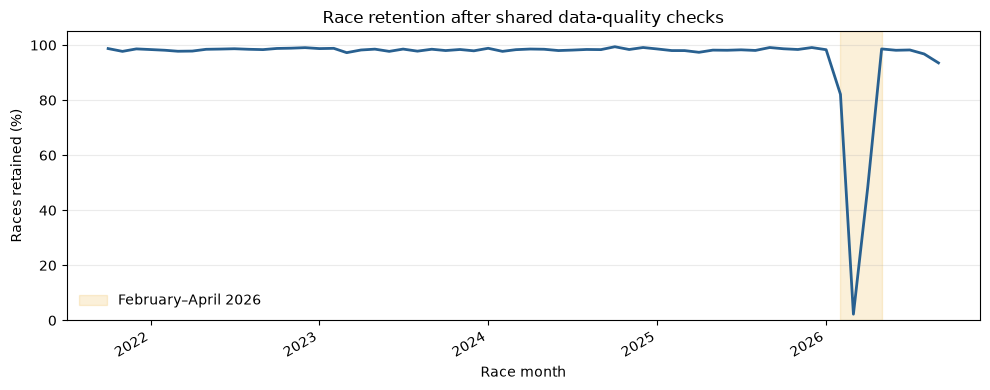

In [29]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    monthly_summary.index.to_timestamp(),
    monthly_summary["model_retention_pct"],
    color="#286090",
    linewidth=2,
)

ax.axvspan(
    pd.Timestamp("2026-02-01"),
    pd.Timestamp("2026-05-01"),
    color="#e69f00",
    alpha=0.15,
    label="February–April 2026",
)

ax.set(
    title="Race retention after shared data-quality checks",
    xlabel="Race month",
    ylabel="Races retained (%)",
    ylim=(0, 105),
)

ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 8. Create the task datasets

| Dataset | Unit and purpose |
|---|---|
| `master` | All joined entries with diagnostic flags; not a model feature matrix |
| `race_quality` | One audit record per race with runner records |
| `model_candidates` | Actual starters in eligible races, including recognised DNFs |
| `q4_candidates` | Eligible single-favourite races, all years |
| `q4_development` | Question 4 races from 2021–2025 |

Favourite failure is an interpretable proxy for unpredictability, not a full measure of market uncertainty. Clarify the favourite snapshot before treating it as a pre-race predictor.

For modelling: train initially on 2021–2024, validate on 2025, and reserve 2026 for final evaluation. Refit on 2021–2025 only once choices are fixed. Select predictors explicitly: current-race commentary, outcomes and performance ratings must not leak into predictions. Fit imputation/encoding on training data only. Historical features must use earlier available information; ambiguous previous outcomes must not silently become losses. History built only from eligible records is incomplete observed history.

In [30]:
model_ids = race_quality.index[race_quality['model_candidate']]
model_candidates = master.loc[
    master['race_instance_uid'].isin(model_ids) & master['is_starter'].fillna(False)
].copy()
model_candidates['field_size_actual'] = model_candidates['race_instance_uid'].map(race_quality['field_size'])
q4_candidates = race_quality.loc[race_quality['q4_candidate']].reset_index().copy()
q4_candidates['favourite_lost'] = 1-q4_candidates['favourite_won']
q4_development = q4_candidates.loc[q4_candidates['year'].between(2021,2025)].copy()

assert model_candidates['is_winner'].notna().all()
assert model_candidates.groupby('race_instance_uid')['is_winner'].sum().eq(1).all()
assert model_candidates.groupby('race_instance_uid').size().eq(race_quality.loc[model_ids,'field_size']).all()
assert q4_candidates['race_instance_uid'].is_unique
print('Model candidate starter rows:', len(model_candidates))
print('Q4 candidate races, all years:', len(q4_candidates))
print('Q4 development races, 2021–2025:', len(q4_development))
print('Eligibility follows the documented initial policy; inspect coverage before use.')


Model candidate starter rows: 614685
Q4 candidate races, all years: 62525
Q4 development races, 2021–2025: 55267
Eligibility follows the documented initial policy; inspect coverage before use.


## 9. Decision log
The log explains **what was decided, why, and the limitation**. It complements the numerical exclusion summary. Conservative exclusions are an intentional initial scope choice, not proof that every excluded record is wrong.

In [31]:
decision_log = pd.DataFrame([
    {
        "topic": "Basic cleaning",
        "decision": "Trim whitespace, standardise blanks, remove exact duplicates.",
        "reason": "Correct formatting and repeated identical records.",
        "limitation": "Do not resolve conflicting records by keeping an arbitrary row.",
    },
    {
        "topic": "Structural integrity",
        "decision": "Exclude affected races with conflicting identifiers or failed joins.",
        "reason": "Race membership and entry counts must be trustworthy.",
        "limitation": "Retain diagnostic records for future investigation.",
    },
    {
        "topic": "Non-runners",
        "decision": "Exclude from starter datasets; accept zero or missing position.",
        "reason": "Zero is the usual non-runner placeholder in this dataset.",
        "limitation": "Participation flags may still be imperfect.",
    },
    {
        "topic": "Known outcomes",
        "decision": "Use valid positions and recognised DNF statuses without conflicts.",
        "reason": "Confirmed DNFs are legitimate non-winners.",
        "limitation": "The DNF flag is empty; interpretation relies on status text.",
    },
    {
        "topic": "Ambiguous outcomes",
        "decision": "Exclude whole races with unexplained outcomes or unrecognised statuses.",
        "reason": "Avoid inventing losses, finishing positions or participation.",
        "limitation": "Some excluded races may be recoverable with clarification.",
    },
    {
        "topic": "Disqualifications and multiple winners",
        "decision": "Exclude affected races from the initial datasets.",
        "reason": "Keep official-result and winner-label interpretation unambiguous.",
        "limitation": "Valid dead heats and some valid results are omitted.",
    },
    {
        "topic": "Field size",
        "decision": "Require a consistent supplied count matching counted starters.",
        "reason": "Field size is central to the analysis.",
        "limitation": "Agreement is a consistency check, not proof of completeness.",
    },
    {
        "topic": "Race eligibility",
        "decision": "Require a usable date, at least two starters and one recognised winner.",
        "reason": "Define the initial competitive-race population.",
        "limitation": "Walkovers and races without usable results are omitted.",
    },
    {
        "topic": "Q4 favourites",
        "decision": "Require known favourite flags and exactly one favourite among starters.",
        "reason": "Provide a clear favourite-success outcome.",
        "limitation": "Conclusions initially apply to single-favourite races.",
    },
    {
        "topic": "2026 coverage",
        "decision": "Apply the same quality rules across years; retain monthly coverage diagnostics.",
        "reason": "Unexplained zero positions concentrate in February–April 2026.",
        "limitation": "Eligible 2026 races are not representative of the full period.",
    },
], columns=["topic", "decision", "reason", "limitation"])

display(decision_log)

,topic,decision,reason,limitation
0,Basic cleaning,"Trim whitespace, standardise blanks, remove ex...",Correct formatting and repeated identical reco...,Do not resolve conflicting records by keeping ...
1,Structural integrity,Exclude affected races with conflicting identi...,Race membership and entry counts must be trust...,Retain diagnostic records for future investiga...
2,Non-runners,Exclude from starter datasets; accept zero or ...,Zero is the usual non-runner placeholder in th...,Participation flags may still be imperfect.
3,Known outcomes,Use valid positions and recognised DNF statuse...,Confirmed DNFs are legitimate non-winners.,The DNF flag is empty; interpretation relies o...
4,Ambiguous outcomes,Exclude whole races with unexplained outcomes ...,"Avoid inventing losses, finishing positions or...",Some excluded races may be recoverable with cl...
5,Disqualifications and multiple winners,Exclude affected races from the initial datasets.,Keep official-result and winner-label interpre...,Valid dead heats and some valid results are om...
6,Field size,Require a consistent supplied count matching c...,Field size is central to the analysis.,"Agreement is a consistency check, not proof of..."
7,Race eligibility,"Require a usable date, at least two starters a...",Define the initial competitive-race population.,Walkovers and races without usable results are...
8,Q4 favourites,Require known favourite flags and exactly one ...,Provide a clear favourite-success outcome.,Conclusions initially apply to single-favourit...
9,2026 coverage,Apply the same quality rules across years; ret...,Unexplained zero positions concentrate in Febr...,Eligible 2026 races are not representative of ...


## 10. Optional export and hand-off
After a successful full run and review of the summaries, set `EXPORT_RESULTS=True` and rerun this cell. It creates a new timestamped folder under `outputs/`; no existing files or database records are overwritten.

Compressed CSV exports do not preserve pandas dtypes. Parse dates and explicitly specify identifier types when loading them. `q4_development` is the next analyst notebook's input; `model_candidates` still requires feature preparation. Outstanding predictor issues (for example implausible ages or rating sentinels) belong in the modelling notebook rather than being global row exclusions here.

In [32]:
if EXPORT_RESULTS:
    out = PROJECT_ROOT / 'outputs' / ('audit_' + pd.Timestamp.now().strftime('%Y%m%d_%H%M%S_%f'))
    out.mkdir(parents=True, exist_ok=False)
    exports = {
        'master_cleaned': master,
        'race_quality': race_quality.reset_index(),
        'model_candidates': model_candidates,
        'q4_candidates': q4_candidates,
        'q4_development': q4_development,
        'decision_log': decision_log,
        'final_exclusion_summary': final_exclusion_summary,
        'exclusion_flow': exclusion_flow,
        'exclusion_reasons': reasons.reset_index(),
        'overlapping_exclusions': overlapping_exclusions.reset_index(),
        'monthly_coverage': monthly_summary.reset_index(),
        'conversion_issues': conversion_issues,
        'structural_runner_rows': structural_runner_rows,
        'conflicting_race_rows': duplicate_races,
        'missing_race_id_rows': missing_race_id_rows,
        'races_without_runner_records': races.loc[races['race_instance_uid'].isin(no_runner_ids)],
        'cleaning_counts': pd.DataFrame(cleaning_log),
    }
    exports.update({f'coverage_by_{name}': frame.reset_index()
                    for name, frame in coverage_tables.items()})
    for name, frame in exports.items():
        frame.to_csv(out / f'{name}.csv.gz', index=False, compression='gzip')
    manifest = {
        'source_database': str(DB_PATH), 'pandas': pd.__version__,
        'policy': 'Conservative initial outcome policy; see decision_log.csv.gz',
        'dnf_statuses': sorted(DNF_STATUSES),
        'non_runner_map': NON_RUNNER_MAP, 'favourite_map': FAVOURITE_MAP,
        'dq_map': DQ_MAP, 'development_years': [2021, 2025], 'test_year': 2026,
    }
    (out / 'manifest.json').write_text(json.dumps(manifest, indent=2), encoding='utf-8')
    print('Exported to:', out)
else:
    print('Exports disabled. The source database has not been modified.')


Exported to: C:\Users\orman\OneDrive\Documents\horse-racing-assignment\outputs\audit_20261016_045639_187839
